In [27]:
import numpy as np
import pandas as pd

In [28]:
dataset=pd.read_csv("Placement.csv")

In [29]:
dataset

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,M,80.60,Others,82.00,Others,Commerce,77.60,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.00,Others,60.00,Others,Science,72.00,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.00,Others,67.00,Others,Commerce,73.00,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.00,Others,66.00,Others,Commerce,58.00,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0


In [30]:
#1.2 1)Replace the NaN values with correct value. And justify why you have chosen the same.

dataset.isna().sum()

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

In [31]:
dataset.isna().sum()

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

In [32]:
# With respect to the problem, we have to replace the missing values with "0", as replacing them with other values in the "salary" column changes the context that the person with the missing value is getting the salary.
dataset["salary"]=dataset["salary"].fillna(0)

In [33]:
dataset.isnull().sum()

sl_no             0
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
salary            0
dtype: int64

In [34]:
2)How many of them are not placed?

(dataset["status"]=="Not Placed").sum()

np.int64(67)

Type:        DataFrame
String form:
sl_no gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p  \
           0        1      M  67.00 <...> 213  Comm&Mgmt     No     70.0         Mkt&HR  60.23  Placed  204000.0
           
           [148 rows x 15 columns]
Length:      148
File:        c:\anaconda3\envs\aiml\lib\site-packages\pandas\__init__.py
Docstring:  
Two-dimensional, size-mutable, potentially heterogeneous tabular data.

Data structure also contains labeled axes (rows and columns).
Arithmetic operations align on both row and column labels. Can be
thought of as a dict-like container for Series objects. The primary
pandas data structure.

Parameters
----------
data : ndarray (structured or homogeneous), Iterable, dict, or DataFrame
    Dict can contain Series, arrays, constants, dataclass or list-like objects. If
    data is a dict, column order follows insertion-order. If a dict contains Series
    which have an index defined, it is aligned by its index. This alignment als

In [35]:
#67 of them are not placed.

In [36]:
#4)What kind of relation between salary and mba_p?
dataset["salary"].corr(dataset["mba_p"])

np.float64(0.13982273892615557)

In [37]:
#The Correlation coefficient between salary and mba_p is 0.13, which indicates a weak positive correlation(relationship).

In [38]:
#5)Which specialization is getting minimum salary?

dataset.groupby('specialisation')['salary'].mean().sort_values()

specialisation
Mkt&HR     150842.105263
Mkt&Fin    236591.666667
Name: salary, dtype: float64

In [39]:
#So,"Mkt&HR" specialisation is getting minimum salary.

In [40]:
# 6)How many of them getting above 500000 salary?

print((dataset["salary"]>50000).sum())

148


In [41]:
#148 of them are getting salary above 50,000.

In [42]:
#7)Test the Analysis of Variance between etest_p and mba_p at significance level 5%.(Make decision using Hypothesis Testing):




In [43]:
#8)Test the similarity between the degree_t(Sci&Tech) and specialisation(Mkt&HR) with respect to salary at significance level of 5%.(Make decision using Hypothesis Testing)
#To test the similarity, we go for hypothesis testing.

#Null Hypothesis: There is no significant difference in the average salaries between Sci&Tech degree students and Mkt&HR specialisation students.

#Alternative Hypothesis: There is a significant difference in the average salaries between the two groups.



In [44]:
#since there are 2 categorical groups and 1 condition, we go for unpaired T-test/independent sample:

from scipy.stats import ttest_ind

group1=dataset[dataset["degree_t"]=="Sci&Tech"]["salary"].dropna()

group2= dataset[dataset["specialisation"]=="Mkt&HR"]["salary"].dropna()

ttest_ind(group1,group2)

TtestResult(statistic=np.float64(2.692041243555374), pvalue=np.float64(0.007897969943471191), df=np.float64(152.0))

In [45]:
#As p value is less than 0.05,There is a significant difference in the average salaries between the two groups.

#Therefore,reject Null Hypothesis and accept Alternative hypothesis.

In [46]:
#9)Convert the normal distribution to standard normal distribution for salary column:






In [47]:
#10)What is the probability Density Function of the salary range from 700000 to 900000?

def get_pdf_probability(dataset,startrange,endrange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns
    ax= sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
    pyplot.axvline(startrange,color="Red")
    pyplot.axvline(endrange,color="Red")
    #generate a sample:
    sample=dataset


  

    #calculating the parameters:
    sample_mean=sample.mean()
    sample_std=sample.std()
    print("Mean=%.3f,Std=%.3f" % (sample_mean,sample_std))
    
    #define the distribution:
    dist=norm(sample_mean,sample_std)
    
    #sample probabilities for a range of outcomes:
    #values= [value for value in range(startrange,endrange)]
    probabilities= [dist.pdf(value) for value in range(startrange,endrange)] #(what to calculate)->pdf(value),(where to find the value)->in range.
    prob= sum(probabilities)
    print("The area between range({},{});{}".format(startrange,endrange,sum(probabilities)))
    return prob


C:\Users\amarp\AppData\Local\Temp\ipykernel_5500\1799243185.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax= sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
Task was destroyed but it is pending!
task: <Task pending name='Task-381' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Anaconda3\envs\aiml\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-382' coro=<Kernel.shell_main() running at C:\Anaconda3\envs\aiml\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Anaconda3\envs\aiml\Lib\site-packages\zmq\e

Mean=198702.326,Std=154780.927
The area between range(700000,900000);0.0005973310593974868


np.float64(0.0005973310593974868)

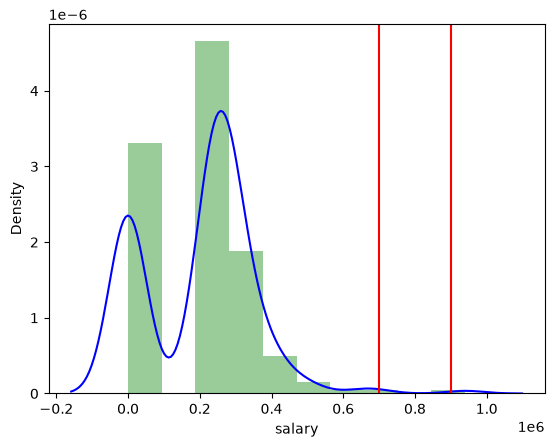

In [48]:
get_pdf_probability(dataset["salary"],700000,900000)

In [49]:
#11)Test the similarity between the degree_t(Sci&Tech)with respect to etest_p and mba_p at significance level of 5%.(Make decision using Hypothesis Testing)

#Null Hypothesis: There is no significant difference between the mean E-test percentage and mean MBA percentage among Sci&Tech degree students.
#Alternative Hypothesis: There is a significant difference between the mean E-test percentage and mean MBA percentage among Sci&Tech degree students.

#one group with 2 conditions, so we do Paired T-test/Dependent sample:


from scipy.stats import ttest_rel

group1= dataset[dataset["degree_t"]=="Sci&Tech"]

group1 = group1[["etest_p","mba_p"]].dropna()


ttest_rel(group1["etest_p"],group1["mba_p"])

TtestResult(statistic=np.float64(5.0049844583693615), pvalue=np.float64(5.5179206005054e-06), df=np.int64(58))

In [50]:
#As p value is lesser than 0.05, there is a significant difference between between the mean E-test percentage and mean MBA percentage among Sci&Tech degree students.

#So,reject Null Hypothesis and accept Alternative Hypothesis.

In [51]:
#12)Which parameter is highly correlated with salary?

dataset.corr(numeric_only=True)["salary"].sort_values(ascending=False)

salary      1.000000
ssc_p       0.538090
hsc_p       0.452569
degree_p    0.408371
etest_p     0.186988
mba_p       0.139823
sl_no       0.002543
Name: salary, dtype: float64

In [ ]:
#Based on the above o/p, it shows that ssc_p parameter is highly correlated with salary.

In [ ]:
#13) plot any useful graph and explain it.



In [52]:
pip install nbconvert

Note: you may need to restart the kernel to use updated packages.


In [56]:
!pandoc --version

pandoc 3.8
Features: +server +lua
Scripting engine: Lua 5.4
User data directory: C:\Users\amarp\AppData\Roaming\pandoc
Copyright (C) 2006-2025 John MacFarlane. Web:  https://pandoc.org
This is free software; see the source for copying conditions. There is no
warranty, not even for merchantability or fitness for a particular purpose.
